(dose-response-guide)=
# Dose response per cell type

Find which genes respond to a dose in each cell type of a dose series, and how, with {api}`dose_response`. The series here is simulated from known curves by {api}`simulate_dose_series`, so its truth says which genes respond: 27 mice, 3 for the vehicle and for each of eight doses from 0.01 to 30 ug/kg in half-log steps, with hepatocytes, macrophages, stellate cells and cholangiocytes, of which 20%, 15%, 5% and 10% of 2,000 genes respond. Hepatocytes and stellate cells fall by half and macrophages double at the top dose, and cholangiocytes are rare. [Dose response](../statistics/dose_response.md) explains the methods.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import (
    CandidateShapes,
    Design,
    DoseAxis,
    DoseTruth,
    Table,
    dose_response,
    read_cube,
)
from cytepool.plotting import plot_dose_response

# The cube, and the truth of each cell type.
cube = read_cube("simulated_dose_series.cube.zarr")
truth = DoseTruth(**json.loads(Path("simulated_dose_series_truth.json").read_text()))
print(f"CytePool {cytepool.__version__}")
print(cube)

CytePool 0.1.1.dev13+g7bb5646dc.d20261120
Cube with 27 samples x 4 groups x 2,000 features
  layers: counts (uint32, lazy)
  filled: 108 of 108 sample x group entries have cells (100.0%)
  samples: sample_id, dose, dose_group, donor
  groups: group_id
  features: feature_id


Each sample is one mouse's pseudobulk profile in one cell type: the sum of its cells' counts. The sample table holds each mouse's `dose`, 0 for the vehicle.

## Place the doses on an axis

Where does each dose sit on the curve's axis? The doses are spaced by half a log10, so the curves follow log10 dose, and the vehicle, whose dose of 0 has no logarithm, forms a group of its own, the default of {api}`DoseAxis`:

In [2]:
axis = DoseAxis("dose", unit=truth.unit, metric=truth.metric)
print(axis)

DoseAxis(column='dose', unit='ug/kg', metric='administered', scale='log10', vehicle='own_group', offset=None)


## Test every cell type

Which genes respond in each cell type? {api}`dose_response` takes the design of the terms other than dose, here none (`"~ 1"`). It checks the design first, as {api}`check_dose_design` does, so that check needs no call of its own, and tests the cell types that support tests:

In [3]:
result = dose_response(cube, Design(cube.samples, "~ 1"), dose=axis)
print(result)

DoseResponseResult (limma_voom): 4 cell types, 3 tested; tests: spline (read
    first), nonlinearity, linear_trend, dose_groups
  dose: ug/kg (administered) on a log10 axis, the vehicle in a group of its own;
        spline of 2 columns, knots at 0.548 ug/kg, boundary knots at 0.01 and 30
        ug/kg; linear_trend slopes per log10 unit of dose
  Hepatocyte: 9 dose groups, 27 samples, 1,869 genes; calls at 5% FDR: spline
              230, nonlinearity 98, linear_trend 205, dose_groups 201
  Macrophage: 9 dose groups, 27 samples, 1,484 genes; calls at 5% FDR: spline
              113, nonlinearity 41, linear_trend 94, dose_groups 104
  Stellate: 9 dose groups, 27 samples, 845 genes; calls at 5% FDR: spline 17,
            nonlinearity 3, linear_trend 12, dose_groups 10
  Cholangiocyte: not tested, descriptive: no treated dose group that can be
                 compared with the vehicle keeps a second sample, so no dose has
                 a replicate


The printout gives the spline's knot in doses and, for each cell type, the dose groups it compares, its samples and genes, and the genes each test calls at 5% FDR. Read `spline` first: it asks whether a gene responds at all. `linear_trend` and `nonlinearity` describe the responses it finds, and `dose_groups` asks the same question as `spline` without a curve. The cholangiocytes are not tested: few of their profiles keep 10 cells, so no dose has a second replicate, and the check calls them descriptive. Its report stays in the result:

In [4]:
report = result.design_report
report.doses.filter(group_id="Cholangiocyte").select(
    ["dose", "n_samples_used", "n_cells_min"]
)

Table with 9 rows and 3 columns
  dose     n_samples_used  n_cells_min
  float64  int64           float64
  0.0      1               17.0
  0.01     0               nan
  0.03     1               13.0
  0.1      0               nan
  0.3      1               10.0
  1.0      1               11.0
  3.0      0               nan
  10.0     1               14.0
  30.0     1               13.0

## Read a test's table

What does each gene's row say? The table of a test has one row per gene that passes the expression filter, here the first five rows of the hepatocytes' spline, sorted by p-value:

In [5]:
# The table of the hepatocytes' spline test, and its five genes of smallest p-value.
spline = result.table("Hepatocyte", "spline")
top = spline.sort("p_value").take(range(5))
print(
    f"{'feature_id':<12}{'f_statistic':>12}{'p_value':>10}{'adjusted_p_value':>18}"
    f"{'adjusted_p_value_across_groups':>32}"
)
for gene, f_statistic, p_value, adjusted, across in zip(
    top["feature_id"],
    top["f_statistic"],
    top["p_value"],
    top["adjusted_p_value"],
    top["adjusted_p_value_across_groups"],
):
    print(
        f"{gene:<12}{f_statistic:>12.1f}{p_value:>10.2g}{adjusted:>18.2g}{across:>32.2g}"
    )

feature_id   f_statistic   p_value  adjusted_p_value  adjusted_p_value_across_groups
gene_0295          163.6   4.5e-19           3.2e-16                         3.6e-16
gene_0896          163.6   4.5e-19           3.2e-16                         3.6e-16
gene_0046          162.1   5.1e-19           3.2e-16                         3.6e-16
gene_0342          111.4   1.1e-16           5.2e-14                         5.2e-14
gene_0708           98.4   6.4e-16           2.4e-13                         2.7e-13


`f_statistic` and `p_value` test the gene; `adjusted_p_value` adjusts the p-values of the cell type by Benjamini-Hochberg, and `adjusted_p_value_across_groups` those of every cell type at once. The table of the linear trend, `result.table("Hepatocyte", "linear_trend")`, has a `log2_fold_change`, the slope of a straight line along the axis, the change per log10 unit of dose, and `result.table("Hepatocyte", "each_dose")` tests each dose against the vehicle.

## Compare the calls with the truth

How many of the genes that respond does each test find, and how many flat genes does it call? The truth knows each gene's maximal change:

In [6]:
for cell_type in ("Hepatocyte", "Macrophage", "Stellate"):
    genes = truth.table(cell_type)
    change = dict(
        zip(genes["feature_id"].tolist(), np.abs(genes["max_log2_change"]).tolist())
    )
    for test in result.tests:
        table = result.table(cell_type, test)
        called = np.asarray(table["adjusted_p_value"]) < 0.05
        responds = np.array([change[g] > 0 for g in table["feature_id"].tolist()])
        print(
            f"{cell_type:<11} {test:<13} {called[responds].sum():>3} of "
            f"{responds.sum()} responsive genes, {called[~responds].sum()} of "
            f"{(~responds).sum()} flat"
        )

Hepatocyte  spline        222 of 378 responsive genes, 8 of 1491 flat
Hepatocyte  nonlinearity   93 of 378 responsive genes, 5 of 1491 flat
Hepatocyte  linear_trend  194 of 378 responsive genes, 11 of 1491 flat
Hepatocyte  dose_groups   194 of 378 responsive genes, 7 of 1491 flat
Macrophage  spline        109 of 223 responsive genes, 4 of 1261 flat
Macrophage  nonlinearity   40 of 223 responsive genes, 1 of 1261 flat
Macrophage  linear_trend   90 of 223 responsive genes, 4 of 1261 flat
Macrophage  dose_groups   100 of 223 responsive genes, 4 of 1261 flat
Stellate    spline         17 of 49 responsive genes, 0 of 796 flat
Stellate    nonlinearity    3 of 49 responsive genes, 0 of 796 flat
Stellate    linear_trend   12 of 49 responsive genes, 0 of 796 flat
Stellate    dose_groups    10 of 49 responsive genes, 0 of 796 flat


With three mice per dose, the spline finds about 6 in 10 of the hepatocytes' responses and calls 8 of their 1,491 flat genes. The stellate cells, with 40 cells per profile, give noisier profiles, and their spline finds about a third of their responses. The non-linearity test calls fewer genes: only the responses that bend away from a straight line along log10 dose, such as bells and steps.

## See the shape of a response

What shape does a response take? {api}`plot_dose_response` draws each dose's estimate against the vehicle, the fitted spline and its 95% band; the true curves are drawn dashed over them:

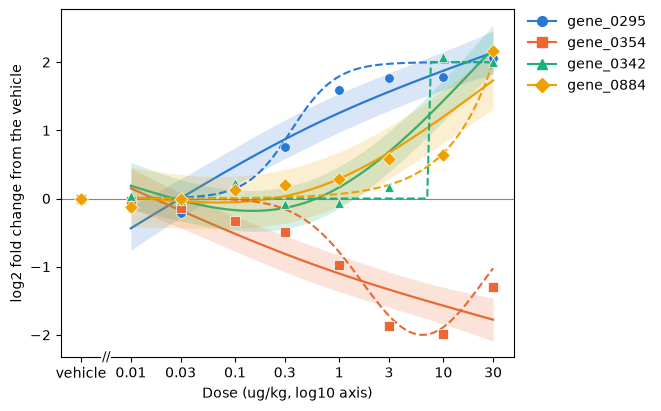

gene_0295: hill, gene_0354: log_gauss_probit, gene_0342: step, gene_0884: linear


In [7]:
called = spline.filter(spline["adjusted_p_value"] < 0.05)
truths = truth.table("Hepatocyte")
shape_of = dict(zip(truths["feature_id"].tolist(), truths["shape"].tolist()))
# The gene of smallest p-value of each of four shapes.
ordered = called.sort("p_value")["feature_id"].tolist()
shapes = ("hill", "log_gauss_probit", "step", "linear")
picked = [next(g for g in ordered if shape_of[g] == shape) for shape in shapes]
ax = plot_dose_response(result, "Hepatocyte", genes=picked)
# The true curves, dashed, in the colours of the fitted ones.
grid = np.geomspace(0.01, 30.0, 100)
true = truth.curve("Hepatocyte", picked, at=grid)
fitted = [line for line in ax.get_lines() if line.get_gid() == "curve"]
for line, values in zip(fitted, true, strict=True):
    ax.plot(axis.positions(grid), values, linestyle="--", color=line.get_color())
plt.show()
print(", ".join(f"{g}: {shape_of[g]}" for g in picked))

A spline of two columns follows its gene's dose groups only as far as its shape allows. The Hill gene (gene_0295) rises more steeply between 0.3 and 3 ug/kg than its spline, which also starts at -0.4 at 0.01 ug/kg, where the true change is 0; its band misses the true curve at 4 of the 8 doses. The bell (gene_0354) turns back above 10 ug/kg while its spline keeps falling, and its band misses the true curve from 0.1 ug/kg up. The step's spline (gene_0342) smooths its jump at 7 ug/kg, and the straight line in dose (gene_0884), which climbs only at the top doses, gets a spline that rises earlier; both bands miss at 3 and 10 ug/kg. A band holds the spline that the true means of the dose groups would give, not every true curve, so read it beside the dose points, which lie closer to the truth. With the vehicle in a group of its own, each curve starts at the lowest dose, a jump from the vehicle's 0 left of the axis break. A larger `spline_df` follows such shapes more closely at some cost in power, and the non-linearity test flags the responses that bend.

## Test a few expected shapes

Does a response follow one of a few expected shapes, or grow with dose? The spline finds responses of any shape. Two multiple contrast tests ask the narrower questions: the MCP step of MCP-Mod tests a few candidate shapes, and the Williams-type test responses that grow in dose order. They take 0.5 to 1.1 ms per gene on two threads, far longer than the spline, so they run only when named in `tests`, here beside it. {api}`CandidateShapes.spread` places the default shapes over the doses, as `dose_response` does when no `candidates` are given:

In [8]:
shapes = CandidateShapes.spread(axis, cube.samples)
print(shapes.names)
shaped = dose_response(
    cube,
    Design(cube.samples, "~ 1"),
    dose=axis,
    tests=("spline", "williams", "mcp"),
    rng=1,
)
print(shaped)

('emax_1', 'emax_2', 'sigmoid_emax', 'exponential', 'beta')


DoseResponseResult (limma_voom): 4 cell types, 3 tested; tests: spline (read
    first), williams, mcp
  dose: ug/kg (administered) on a log10 axis, the vehicle in a group of its own;
        spline of 2 columns, knots at 0.548 ug/kg, boundary knots at 0.01 and 30
        ug/kg
  Hepatocyte: 9 dose groups, 27 samples, 1,869 genes; calls at 5% FDR: spline
              230, williams 172, mcp 235
  Macrophage: 9 dose groups, 27 samples, 1,484 genes; calls at 5% FDR: spline
              113, williams 92, mcp 121
  Stellate: 9 dose groups, 27 samples, 845 genes; calls at 5% FDR: spline 17,
            williams 11, mcp 18
  Cholangiocyte: not tested, descriptive: no treated dose group that can be
                 compared with the vehicle keeps a second sample, so no dose has
                 a replicate


Two Emax shapes rise early and midway along log dose, the sigmoid Emax shape rises steeply midway, the exponential shape late, and the beta shape rises to a peak midway and falls. `rng` seeds the multivariate t probabilities, so the p-values reproduce. Which responses does each test find? Count the calls at 5% FDR by true shape:

In [9]:
genes = truth.table("Hepatocyte")
shape_of = dict(zip(genes["feature_id"].tolist(), genes["shape"].tolist()))
order = [
    "hill",
    "exponential",
    "linear",
    "power",
    "log_gauss_probit",
    "frechet",
    "step",
]
tested = shaped.table("Hepatocyte", "spline")["feature_id"].tolist()
counts = {
    "shape": order,
    "responsive": [sum(shape_of[g] == s for g in tested) for s in order],
}
for test in ("spline", "williams", "mcp"):
    table = shaped.table("Hepatocyte", test)
    called = set(table.filter(table["adjusted_p_value"] < 0.05)["feature_id"].tolist())
    counts[test] = [
        sum(g in called and shape_of[g] == s for g in tested) for s in order
    ]
Table(counts)

Table with 7 rows and 5 columns
  shape             responsive  spline  williams  mcp
  str               int64       int64   int64     int64
  hill              112         56      46        55
  exponential       55          29      22        27
  linear            20          11      9         13
  power             36          17      15        22
  log_gauss_probit  77          56      35        54
  frechet           39          25      17        25
  step              39          28      21        27

The MCP step calls 235 of the hepatocytes' genes and the spline 230, and both find most of the 77 bells, the `log_gauss_probit` curves that rise and fall back: 54 and 56, the MCP step through its beta shape, an umbrella. The Williams-type test calls 172, and 35 of the bells: it pools the top doses, where a bell has fallen back.

## Find the lowest dose with an effect

From which dose does each gene respond? {api}`DoseResponseResult.lowest_effective_doses` calls each dose against the vehicle in the genes the spline calls, at the level that leaves the false discovery rate of the genes at 5%, and gives the lowest dose called:

In [10]:
lowest = shaped.lowest_effective_doses("Hepatocyte")
called = lowest.filter(lowest["responds"])
with_dose = called.filter(np.isfinite(np.asarray(called["lowest_effective_dose"])))
print(f"{len(called)} genes respond; {len(with_dose)} have a dose called")
# The five genes of smallest stage-wise adjusted p-value, rounded.
top = called.sort("stage_wise_adjusted_p_value").take(range(5))
for gene, dose, change, p, n in zip(
    top["feature_id"],
    top["lowest_effective_dose"],
    top["log2_fold_change"],
    top["stage_wise_adjusted_p_value"],
    top["n_doses_called"],
):
    print(f"{gene}  {dose:>4g} ug/kg  {change:+.1f} log2  p {p:.2g}  {n} of 8 doses")

230 genes respond; 165 have a dose called
gene_0018    30 ug/kg  +2.0 log2  p 5.9e-13  1 of 8 doses
gene_0553    30 ug/kg  +1.9 log2  p 4.3e-11  1 of 8 doses
gene_0342    10 ug/kg  +2.1 log2  p 5.5e-11  2 of 8 doses
gene_0896   0.3 ug/kg  +1.7 log2  p 3e-10  5 of 8 doses
gene_0603    10 ug/kg  +2.4 log2  p 4.5e-10  2 of 8 doses


Of the 230 genes that the spline calls, 165 have a dose called. Each line gives a gene's lowest effective dose, the lowest dose called, with its change from the vehicle and its stage-wise adjusted p-value, and how many of the 8 treated doses are called: the table's columns `lowest_effective_dose`, `log2_fold_change`, `stage_wise_adjusted_p_value` and `n_doses_called`. A gene can respond with no dose called, when its change spreads over several doses that each fall short. How do these doses compare with the truth?

In [11]:
ids = with_dose["feature_id"].tolist()
doses = np.asarray(with_dose["lowest_effective_dose"])
true_change = np.array(
    [truth.curve("Hepatocyte", [g], at=[d])[0, 0] for g, d in zip(ids, doses)]
)
bmd = dict(zip(genes["feature_id"].tolist(), np.asarray(genes["bmd_fold_change"])))
ratio = np.array([d / bmd[g] for g, d in zip(ids, doses)])
print(
    f"true change at the lowest effective dose: median {np.median(np.abs(true_change)):.2f} log2"
)
print(
    f"lowest effective dose over the true 1.1-fold BMD: median {np.nanmedian(ratio):.1f}"
)

true change at the lowest effective dose: median 1.00 log2
lowest effective dose over the true 1.1-fold BMD: median 7.3


At its lowest effective dose a gene had changed by a median of 1.00 log2 in truth, twofold, and every such dose lay above the gene's true benchmark dose of a 1.1-fold change, by a median factor of 7.3. The lowest effective dose is the lowest tested dose at which the change is detectable with three mice per dose, not the dose where the response starts: a response that starts between two doses, or changes less at the lower doses than three replicates can detect, is called only at a higher dose. Two of the 165 genes with a dose called are flat in truth, false calls that the overall false discovery rate of 5% allows.

## Read next

[Which genes respond to dose](../statistics/dose_response.md#dose-response-tests) explains the four tests and how they share one fit, [Curves with a band](../statistics/dose_response.md#dose-response-curves) the curves, and [Checking a dose design](../statistics/dose_response.md#dose-design-check) the statuses of the check. [Simulated dose series with known curves](../statistics/dose_response.md#simulated-dose-series) draws series like this one at other designs, to see what a design finds before it is run. [Trends, doses against the vehicle and candidate shapes](../statistics/dose_response.md#dose-response-contrasts) explains the multiple contrast tests, and [From which dose a gene responds](../statistics/dose_response.md#lowest-effective-dose) the lowest effective doses.